In [1]:
# PRACTICAL 1: DATA INTAKE

import pandas as pd

df = pd.read_csv("car_data.csv")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())

Total Rows: 301
Total Columns: 9

--- Data Types ---
Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
dtype: object

--- First 5 Rows ---


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0



--- Missing Values ---
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [2]:
# PRACTICAL 2 (Part A): DATA PREPROCESSING & DESCRIPTIVE STATISTICS

# Calculate car age
df['Age'] = 2026 - df['Year']

# Select numerical columns
cols = ['Selling_Price', 'Present_Price', 'Kms_Driven', 'Age']

# Calculate descriptive statistics
stats = pd.DataFrame(index=cols)

stats['Mean'] = df[cols].mean()
stats['Median'] = df[cols].median()
stats['Std_Dev'] = df[cols].std()
stats['Variance'] = df[cols].var()
stats['Min'] = df[cols].min()
stats['Max'] = df[cols].max()
stats['IQR'] = df[cols].quantile(0.75) - df[cols].quantile(0.25)
stats['Skewness'] = df[cols].skew()

display(round(stats, 2))

# Display categorical distributions
print("\n--- Categorical Variable Distributions ---")

for col in ['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']:
    print("\n", col, "Distribution:")
    print(df[col].value_counts(normalize=True).round(4) * 100)


,Mean,Median,Std_Dev,Variance,Min,Max,IQR,Skewness
Selling_Price,4.66,3.6,5.08,2.583000e+01,0.10,35.0,5.1,2.49
Present_Price,7.63,6.4,8.64,7.472000e+01,0.32,92.6,8.7,4.08
Kms_Driven,36947.21,32000.0,38886.88,1.512190e+09,500.00,500000.0,33767.0,6.44
Age,12.37,12.0,2.89,8.360000e+00,8.00,23.0,4.0,1.25



--- Categorical Variable Distributions ---

 Fuel_Type Distribution:
Fuel_Type
Petrol    79.40
Diesel    19.93
CNG        0.66
Name: proportion, dtype: float64

 Seller_Type Distribution:
Seller_Type
Dealer        64.78
Individual    35.22
Name: proportion, dtype: float64

 Transmission Distribution:
Transmission
Manual       86.71
Automatic    13.29
Name: proportion, dtype: float64

 Owner Distribution:
Owner
0    96.35
1     3.32
3     0.33
Name: proportion, dtype: float64


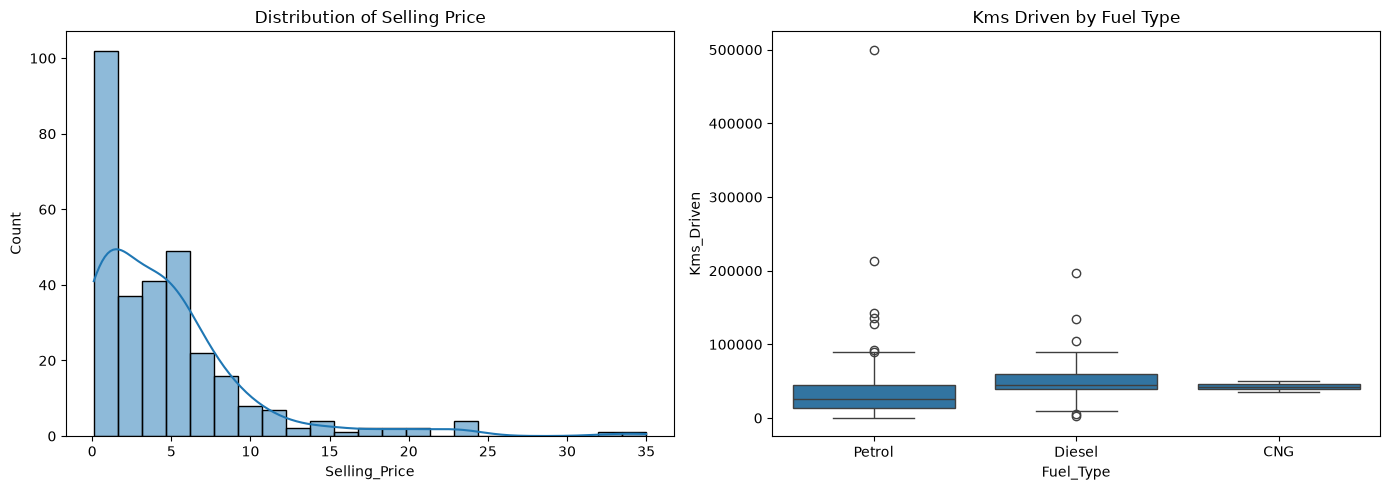

In [3]:
# PRACTICAL 2 (Part B): STATISTICAL VISUALIZATIONS

import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure and 1D axes array
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot distribution of Selling Price
sns.histplot(df['Selling_Price'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of Selling Price')

# Plot Kms Driven by Fuel Type
sns.boxplot(data=df, x='Fuel_Type', y='Kms_Driven', ax=axes[1])
axes[1].set_title('Kms Driven by Fuel Type')

plt.tight_layout()
plt.show()

Original Skewness: 2.493
Log Skewness: -0.474


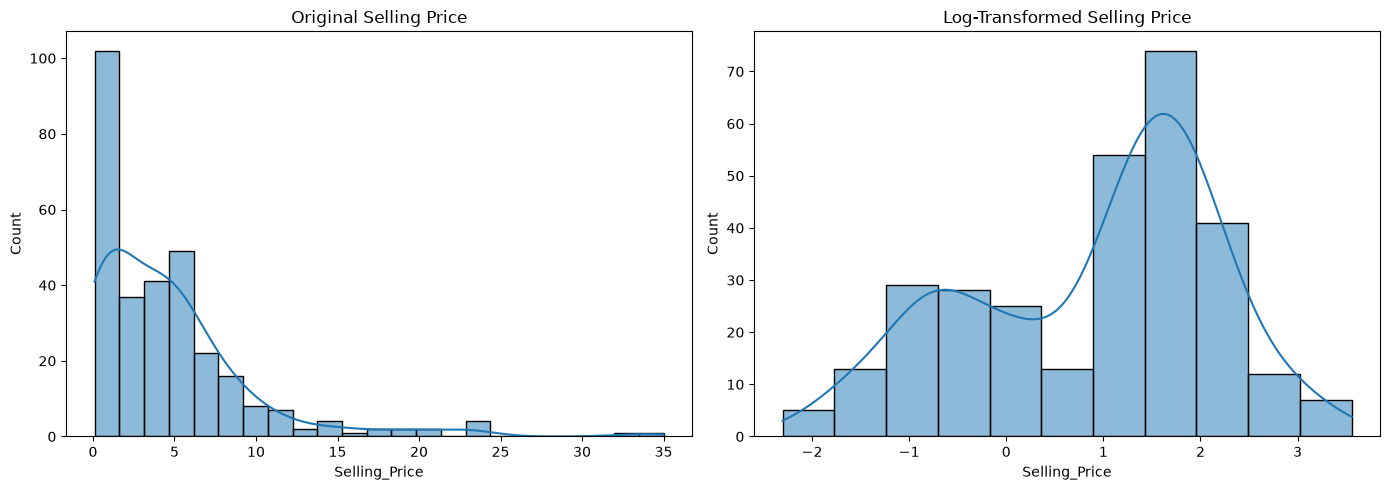

C:\Users\ffsd\AppData\Local\Temp\ipykernel_6288\642009618.py:34: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stratified = df.groupby('Fuel_Type', group_keys=False).apply(


,Metric,Mean Selling Price,Mean Kms Driven
0,Population,4.66,36947.21
1,Simple Random Sample,3.84,35812.56
2,Stratified Sample,4.49,34723.44
3,Systematic Sample,5.20,30974.68


In [4]:
# PRACTICAL 3: PROBABILITY DISTRIBUTIONS & RANDOM SAMPLING

import numpy as np

df['Age'] = 2026 - df['Year']

# PART A: PROBABILITY DISTRIBUTIONS

price = df['Selling_Price']
log_price = np.log(price)

print("Original Skewness:", round(price.skew(), 3))
print("Log Skewness:", round(log_price.skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for data, ax, title, color in [
    (price, axes[0], "Original Selling Price", 'black'),
    (log_price, axes[1], "Log-Transformed Selling Price", 'red')
]:
    sns.histplot(data, kde=True, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

# PART B: RANDOM SAMPLING

size = 50
np.random.seed(42)

srs = df.sample(n=size, random_state=42)

stratified = df.groupby('Fuel_Type', group_keys=False).apply(
    lambda x: x.sample(frac=size / len(df), random_state=42)
)

k = len(df) // size
systematic = df.iloc[np.random.randint(0, k)::k][:size]

comparison = pd.DataFrame({
    'Metric': ['Population', 'Simple Random Sample', 'Stratified Sample', 'Systematic Sample'],
    'Mean Selling Price': [
        df['Selling_Price'].mean(), srs['Selling_Price'].mean(),
        stratified['Selling_Price'].mean(), systematic['Selling_Price'].mean()
    ],
    'Mean Kms Driven': [
        df['Kms_Driven'].mean(), srs['Kms_Driven'].mean(),
        stratified['Kms_Driven'].mean(), systematic['Kms_Driven'].mean()
    ]
})

display(comparison.round(2))

Population Mean: 4.661
Population Std: 5.074


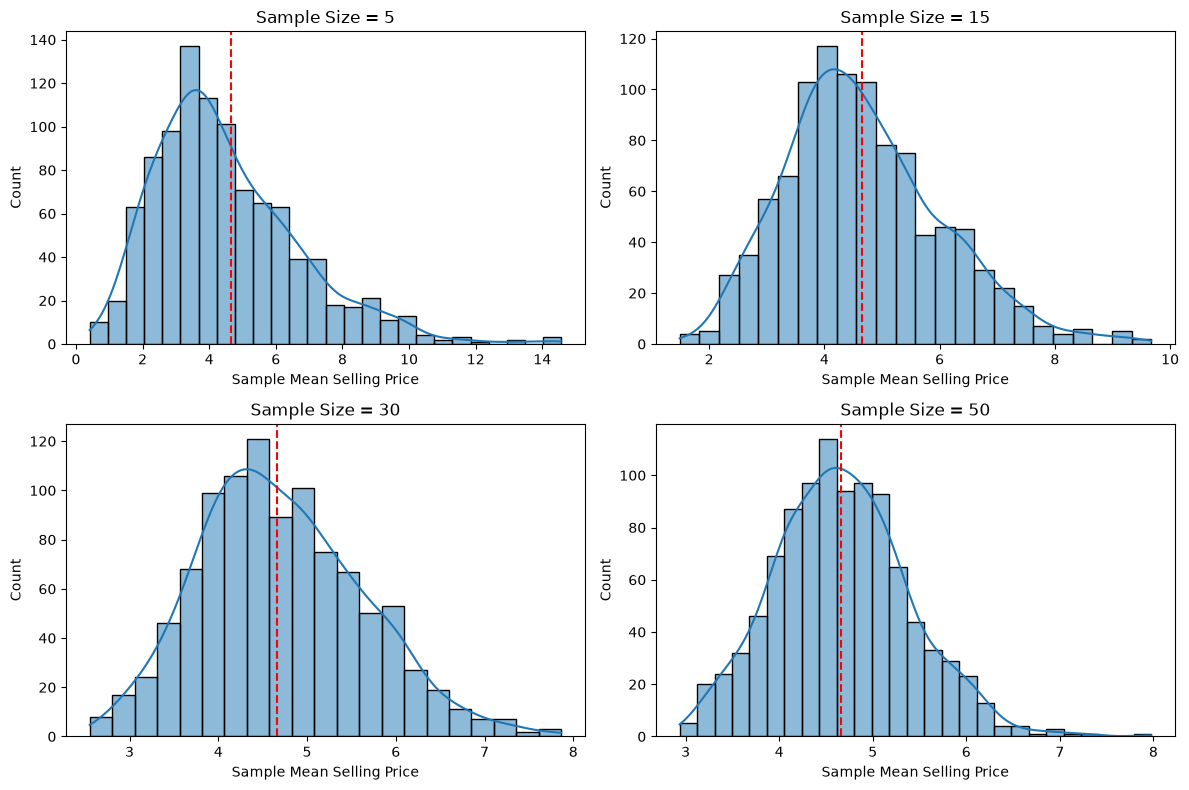

,Sample Size,Mean,Empirical SE,Theoretical SE,Skewness
0,5,4.519,2.184,2.269,1.064
1,15,4.663,1.355,1.310,0.605
2,30,4.708,0.924,0.926,0.407
3,50,4.670,0.721,0.718,0.362


In [5]:
# PRACTICAL 4: CENTRAL LIMIT THEOREM (CLT)

import scipy.stats as sp_stats

population = df['Selling_Price'].values
pop_mean = np.mean(population)
pop_std = np.std(population)

print("Population Mean:", round(pop_mean, 3))
print("Population Std:", round(pop_std, 3))

np.random.seed(42)
summary = []

plt.figure(figsize=(12, 8))

for i, n in enumerate([5, 15, 30, 50], 1):
    means = [np.mean(np.random.choice(population, n)) for _ in range(1000)]

    summary.append([
        n, np.mean(means), np.std(means),
        pop_std / np.sqrt(n), sp_stats.skew(means)
    ])

    plt.subplot(2, 2, i)
    sns.histplot(means, kde=True)
    plt.axvline(pop_mean, color='red', linestyle='--')
    plt.title(f'Sample Size = {n}')
    plt.xlabel('Sample Mean Selling Price')

plt.tight_layout()
plt.show()

clt_df = pd.DataFrame(summary, columns=[
    'Sample Size', 'Mean', 'Empirical SE', 'Theoretical SE', 'Skewness'
])

display(clt_df.round(3))

In [6]:
# PRACTICAL 5: CONFIDENCE INTERVALS & HYPOTHESIS TESTING

import scipy.stats as sp_stats
from statsmodels.stats.weightstats import ztest

# PART A: CONFIDENCE INTERVALS

price = df['Selling_Price']
n = len(price)
mean = price.mean()
sem = price.std() / np.sqrt(n)

print("Sample Size:", n)
print("Sample Mean:", round(mean, 2))
print("95% CI:", sp_stats.t.interval(0.95, df=n-1, loc=mean, scale=sem))
print("99% CI:", sp_stats.t.interval(0.99, df=n-1, loc=mean, scale=sem))

# PART B: ONE-SAMPLE TESTS

z, p = ztest(price, value=5)
print("\nZ-Test:", z, p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to Reject H0")

t, p = sp_stats.ttest_1samp(price, popmean=5)
print("T-Test:", t, p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to Reject H0")

# PART C: TWO-SAMPLE T-TEST

petrol = df[df['Fuel_Type'] == 'Petrol']['Selling_Price']
diesel = df[df['Fuel_Type'] == 'Diesel']['Selling_Price']

t, p = sp_stats.ttest_ind(petrol, diesel, equal_var=False)

print("\nPetrol Mean:", round(petrol.mean(), 2))
print("Diesel Mean:", round(diesel.mean(), 2))
print("T-Statistic:", t)
print("P-Value:", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to Reject H0")

Sample Size: 301
Sample Mean: 4.66
95% CI: (np.float64(4.084762308905346), np.float64(5.2378290532209))
99% CI: (np.float64(3.9018289220349494), np.float64(5.4207624400912975))

Z-Test: -1.1561121720816971 0.24763527787410478
Decision: Fail to Reject H0
T-Test: -1.1561121720816971 0.248555126031397
Decision: Fail to Reject H0

Petrol Mean: 3.26
Diesel Mean: 10.28
T-Statistic: -7.38726365732148
P-Value: 3.652339606029364e-10
Decision: Reject H0


In [7]:
# PRACTICAL 6: CORRELATION, CHI-SQUARE & TWO-WAY ANOVA

import scipy.stats as sp_stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# PART A: COVARIANCE & CORRELATION

cols = ['Selling_Price', 'Present_Price', 'Kms_Driven', 'Age']

display(df[cols].cov().round(2))

for col in ['Present_Price', 'Kms_Driven', 'Age']:
    print(col, "Pearson:", sp_stats.pearsonr(df[col], df['Selling_Price']))
    print(col, "Spearman:", sp_stats.spearmanr(df[col], df['Selling_Price']))

# PART B: CHI-SQUARE TEST

table = pd.crosstab(df['Fuel_Type'], df['Transmission'])
display(table)

chi2, p, dof, expected = sp_stats.chi2_contingency(table)

print("Chi-Square:", chi2)
print("Degrees of Freedom:", dof)
print("P-Value:", p)
print("Decision:", "Reject H0" if p < 0.05 else "Fail to Reject H0")

# PART C: TWO-WAY ANOVA

model = ols('Selling_Price ~ C(Fuel_Type) * C(Transmission)', data=df).fit()
display(sm.stats.anova_lm(model, typ=2).round(4))

,Selling_Price,Present_Price,Kms_Driven,Age
Selling_Price,25.83,38.62,5.768970e+03,-3.47
Present_Price,38.62,74.72,6.845447e+04,1.19
Kms_Driven,5768.97,68454.47,1.512190e+09,58958.87
Age,-3.47,1.19,5.895887e+04,8.36


Present_Price Pearson: PearsonRResult(statistic=np.float64(0.8789825451614953), pvalue=np.float64(3.602186428727221e-98))
Present_Price Spearman: SignificanceResult(statistic=np.float64(0.9082507619600164), pvalue=np.float64(3.7093475464978126e-115))
Kms_Driven Pearson: PearsonRResult(statistic=np.float64(0.029187090674291278), pvalue=np.float64(0.6139960232686597))
Kms_Driven Spearman: SignificanceResult(statistic=np.float64(0.14634252073224346), pvalue=np.float64(0.011019366981871406))
Age Pearson: PearsonRResult(statistic=np.float64(-0.23614098016042734), pvalue=np.float64(3.495472434809087e-05))
Age Spearman: SignificanceResult(statistic=np.float64(-0.28262000354180555), pvalue=np.float64(6.200516784349977e-07))


Transmission,Automatic,Manual
Fuel_Type,,
CNG,0,2
Diesel,12,48
Petrol,28,211


Chi-Square: 3.1651347408583015
Degrees of Freedom: 2
P-Value: 0.20544696207924226
Decision: Fail to Reject H0


C:\Users\ffsd\AppData\Local\Temp\ipykernel_6288\3826899612.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = ols('Selling_Price ~ C(Fuel_Type) * C(Transmission)', data=df).fit()


,sum_sq,df,F,PR(>F)
C(Fuel_Type),4216.0798,2.0,168.5678,0.0
C(Transmission),759.6539,1.0,60.7451,0.0
C(Fuel_Type):C(Transmission),928.6016,2.0,37.1275,0.0
Residual,3701.6547,296.0,NaN,NaN


Simple Linear Regression
Intercept: 0.7185
Slope: 0.5168
R2 Score: 0.7726


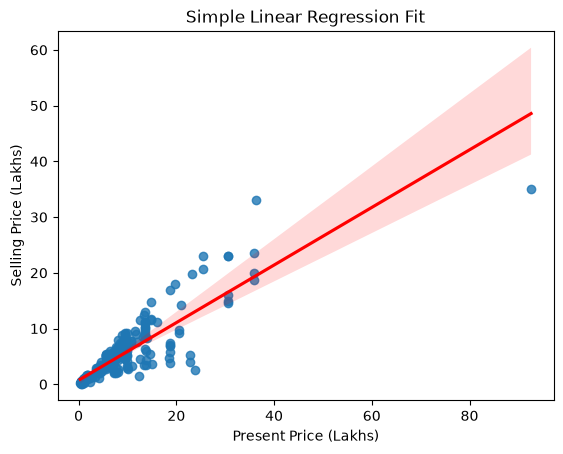


Multiple Linear Regression
Intercept: 7.0275
R2 Score: 0.8541
Mean Squared Error: 3.3602


,Predictor,Coefficient
0,Present_Price,0.4268
1,Kms_Driven,-0.0000
2,Age,-0.3696
3,Fuel_Type_Diesel,2.5349
4,Fuel_Type_Petrol,0.7063
5,Seller_Type_Individual,-1.2533
6,Transmission_Manual,-1.6005


In [8]:
# PRACTICAL 7: LINEAR & MULTIPLE REGRESSION

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df['Age'] = 2026 - df['Year']
y = df['Selling_Price']

# PART A: SIMPLE LINEAR REGRESSION
X = df[['Present_Price']]
model1 = LinearRegression().fit(X, y)
pred1 = model1.predict(X)

print("Simple Linear Regression")
print("Intercept:", round(model1.intercept_, 4))
print("Slope:", round(model1.coef_[0], 4))
print("R2 Score:", round(r2_score(y, pred1), 4))

sns.regplot(x='Present_Price', y='Selling_Price', data=df,
            line_kws={'color': 'red'})
plt.title("Simple Linear Regression Fit")
plt.xlabel("Present Price (Lakhs)")
plt.ylabel("Selling Price (Lakhs)")
plt.show()

# PART B: MULTIPLE LINEAR REGRESSION
X = pd.get_dummies(df[['Present_Price', 'Kms_Driven', 'Age',
                       'Fuel_Type', 'Seller_Type', 'Transmission']],
                   drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model2 = LinearRegression().fit(X_train, y_train)
pred2 = model2.predict(X_test)

print("\nMultiple Linear Regression")
print("Intercept:", round(model2.intercept_, 4))
print("R2 Score:", round(r2_score(y_test, pred2), 4))
print("Mean Squared Error:", round(mean_squared_error(y_test, pred2), 4))

display(pd.DataFrame({
    'Predictor': X.columns,
    'Coefficient': model2.coef_
}).round(4))

R2 Score: 0.8541
MAE: 1.1872
MSE: 3.3602
RMSE: 1.8331


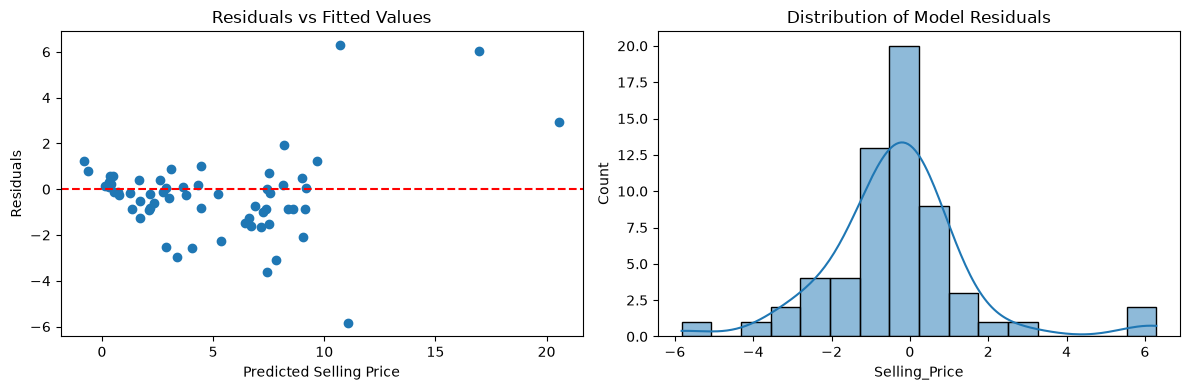

,Model,R2 Score,RMSE
0,Linear Regression,0.8541,1.8331
1,Ridge,0.8549,1.8283
2,Lasso,0.8490,1.8653


Model exported successfully!


In [9]:
# PRACTICAL 8: MODEL DIAGNOSTICS, EVALUATION & EXPORT

import joblib
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# PART A: MODEL EVALUATION
y_pred = model2.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))

# PART B: RESIDUAL DIAGNOSTICS
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_pred, residuals)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title("Residuals vs Fitted Values")
axes[0].set_xlabel("Predicted Selling Price")
axes[0].set_ylabel("Residuals")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Model Residuals")
plt.tight_layout()
plt.show()

# PART C: RIDGE AND LASSO
ridge = Ridge(alpha=1.0).fit(X_train, y_train)
lasso = Lasso(alpha=0.1).fit(X_train, y_train)

models = [model2, ridge, lasso]
names = ['Linear Regression', 'Ridge', 'Lasso']

comparison = pd.DataFrame({
    'Model': names,
    'R2 Score': [r2_score(y_test, m.predict(X_test)) for m in models],
    'RMSE': [np.sqrt(mean_squared_error(y_test, m.predict(X_test))) for m in models]
})
display(comparison.round(4))

# PART D: EXPORT MODEL FOR GRADIO
joblib.dump({
    'model': model2,
    'feature_columns': list(X_train.columns)
}, 'car_price_model.pkl')

print("Model exported successfully!")

In [10]:
# PART A: EVALUATION AND COMPARISON OF FOUR REGRESSION MODELS

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Prepare Simple Linear Regression data
X_simple = df[['Present_Price']]
y = df['Selling_Price']

# Train and test the simple regression data
X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Create the four models
models = {
    "Simple Linear Regression": LinearRegression(),
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1)
}

# Train and evaluate the models
results = []

for name, model in models.items():

    if name == "Simple Linear Regression":
        model.fit(X_simple_train, y_simple_train)
        y_pred = model.predict(X_simple_test)
        y_actual = y_simple_test
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_actual = y_test

    mse = mean_squared_error(y_actual, y_pred)

    results.append({
        "Model": name,
        "R² Score": round(r2_score(y_actual, y_pred), 4),
        "MAE": round(mean_absolute_error(y_actual, y_pred), 4),
        "MSE": round(mse, 4),
        "RMSE": round(np.sqrt(mse), 4)
    })

# Display comparison table
results_df = pd.DataFrame(results)

print("Regression Model Performance Comparison")
display(results_df)

Regression Model Performance Comparison


,Model,R² Score,MAE,MSE,RMSE
0,Simple Linear Regression,0.6874,1.8069,7.2020,2.6837
1,Multiple Linear Regression,0.8541,1.1872,3.3602,1.8331
2,Ridge Regression,0.8549,1.1841,3.3427,1.8283
3,Lasso Regression,0.8490,1.2103,3.4793,1.8653


In [11]:
# Best Model Selection

best_model = ""
best_r2 = -1
best_rmse = float("inf")

models = {
    "Simple Linear Regression": model1,
    "Multiple Linear Regression": model2,
    "Ridge Regression": ridge,
    "Lasso Regression": lasso
}

for name, model in models.items():

    if name == "Simple Linear Regression":
        y_pred = model.predict(X_simple_test)
        actual = y_simple_test
    else:
        y_pred = model.predict(X_test)
        actual = y_test

    r2 = r2_score(actual, y_pred)
    rmse = np.sqrt(mean_squared_error(actual, y_pred))

    print(name)
    print("R² Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print()

    if r2 > best_r2 or (r2 == best_r2 and rmse < best_rmse):
        best_model = name
        best_r2 = r2
        best_rmse = rmse

print("Best Model:", best_model)
print("Best R² Score:", round(best_r2, 4))
print("Best RMSE:", round(best_rmse, 4))

Simple Linear Regression
R² Score: 0.6895
RMSE: 2.6744

Multiple Linear Regression
R² Score: 0.8541
RMSE: 1.8331

Ridge Regression
R² Score: 0.8549
RMSE: 1.8283

Lasso Regression
R² Score: 0.849
RMSE: 1.8653

Best Model: Ridge Regression
Best R² Score: 0.8549
Best RMSE: 1.8283


In [12]:

# AUTOVISION: FULL-SCREEN GRADIENT CAR PRICE PREDICTION

import gradio as gr
import pandas as pd
import joblib

# Load trained model
bundle = joblib.load("car_price_model.pkl")
model = bundle["model"]
columns = bundle["feature_columns"]


# Prediction function
def predict_price(present_price, kms_driven, fuel_type,
                  seller_type, transmission, age):

    if present_price is None or present_price <= 0:
        return "Invalid price", "Enter a price greater than zero."

    if kms_driven is None or kms_driven < 0:
        return "Invalid distance", "Enter valid kilometers driven."

    data = pd.DataFrame([{
        "Present_Price": present_price,
        "Kms_Driven": kms_driven,
        "Age": age,
        "Fuel_Type": fuel_type,
        "Seller_Type": seller_type,
        "Transmission": transmission
    }])

    data = pd.get_dummies(data).reindex(columns=columns, fill_value=0)
    price = max(0, float(model.predict(data)[0]))

    return f"₹ {price:.2f} Lakhs", (
        f"Valuation complete | Age: {age} years | "
        f"Distance: {kms_driven:,.0f} km"
    )


# Gradient dashboard styling
css = """
html, body, .gradio-container {
    margin: 0 !important;
    padding: 0 !important;
    width: 100% !important;
    max-width: 100% !important;
    min-height: 100vh !important;
    background: #080817 !important;
    color: white !important;
    font-family: Arial, sans-serif !important;
}

.gradio-container {
    background:
        radial-gradient(ellipse at top left, #49207888, transparent 40%),
        radial-gradient(ellipse at bottom right, #006b9b66, transparent 45%),
        #080817 !important;
}

#app {
    max-width: 1550px;
    margin: auto;
    padding: 28px 4%;
}

#hero {
    padding: 42px;
    border-radius: 26px;
    border: 1px solid #ffffff25;
    background: linear-gradient(115deg, #261347, #111d3c, #063746);
    margin-bottom: 24px;
}

#hero h1 {
    font-size: clamp(34px, 5vw, 60px);
    font-weight: 900;
    margin: 14px 0;
    color: white;
}

.gradient {
    background: linear-gradient(90deg, #b68aff, #41e8ff, #ff79d5);
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
}

.eyebrow {
    color: #53eaff;
    font-size: 12px;
    font-weight: 800;
    letter-spacing: 3px;
}

.card {
    background: linear-gradient(145deg, #17172eee, #101323ee) !important;
    border: 1px solid #ffffff20 !important;
    border-radius: 22px !important;
    padding: 25px !important;
}

label {
    color: #d0d7f0 !important;
}

input {
    background: #0b1020 !important;
    color: white !important;
    border: 1px solid #383854 !important;
    border-radius: 10px !important;
}

/* Visible, full-width option buttons */
.choice-row {
    display: flex !important;
    flex-direction: row !important;
    flex-wrap: wrap !important;
    gap: 12px !important;
}

.choice-row label {
    flex: 1 1 100px !important;
    min-width: 90px !important;
    padding: 14px 12px !important;
    border: 1px solid #44415f !important;
    border-radius: 12px !important;
    background: #17182b !important;
    color: #e8e9ff !important;
    text-align: center !important;
    cursor: pointer !important;
}

.choice-row label:has(input:checked) {
    background: linear-gradient(110deg, #773bdb, #087eaa) !important;
    border-color: #76e9ff !important;
    box-shadow: 0 0 18px #6655ff44 !important;
}

.choice-row input {
    accent-color: #56eaff !important;
}

#predict {
    min-height: 58px !important;
    border: none !important;
    border-radius: 13px !important;
    background: linear-gradient(100deg, #7747ff, #bd45ff, #00cbe8) !important;
    color: white !important;
    font-weight: 900 !important;
    font-size: 16px !important;
}

#result {
    border: 1px solid #8261ff66 !important;
    border-radius: 22px !important;
    padding: 25px !important;
    background: radial-gradient(ellipse at top right, #6736a944, transparent 55%), #101326 !important;
}

#price textarea {
    min-height: 90px !important;
    font-size: 36px !important;
    font-weight: 900 !important;
    text-align: center !important;
    color: #59edff !important;
    background: #090d1b !important;
    border: 1px solid #5546a5 !important;
}

#reset {
    border: 1px solid #ffffff33 !important;
    border-radius: 12px !important;
    background: #ffffff0a !important;
    color: white !important;
}

@media(max-width: 700px) {
    #app { padding: 12px; }
    #hero { padding: 24px; }
    .card { padding: 16px !important; }
}
"""

theme = gr.themes.Base(
    primary_hue="violet",
    secondary_hue="cyan",
    neutral_hue="slate"
)

with gr.Blocks(
    theme=theme,
    css=css,
    title="AutoVision AI"
) as demo:

    with gr.Column(elem_id="app"):

        gr.HTML("""
        <div id="hero">
            <div class="eyebrow">✦ AUTOMOTIVE INTELLIGENCE</div>
            <h1>Discover Your Car's<br>
            <span class="gradient">Real Worth.</span></h1>
            <p style="color:#c3c9e3;line-height:1.8">
                Next-generation vehicle valuation powered by Machine Learning.
                Configure your vehicle and discover its estimated resale price.
            </p>
        </div>
        """)

        with gr.Row(equal_height=True):

            with gr.Column(scale=11, elem_classes=["card"]):

                gr.Markdown("## 🚘 Vehicle Details")

                with gr.Row():
                    present_price = gr.Number(
                        label="Present Price (₹ Lakhs)",
                        value=8.5,
                        minimum=0.01
                    )

                    age = gr.Slider(
                        0, 25, value=5, step=1,
                        label="Car Age (Years)"
                    )

                kms_driven = gr.Number(
                    label="Kilometers Driven",
                    value=35000,
                    minimum=0
                )

                gr.Markdown("### ⛽ Fuel Type")

                fuel_type = gr.Radio(
                    choices=["Petrol", "Diesel", "CNG"],
                    value="Petrol",
                    type="value",
                    interactive=True,
                    elem_classes=["choice-row"],
                    show_label=False
                )

                gr.Markdown("### 🏷️ Seller Category")

                seller_type = gr.Radio(
                    choices=["Dealer", "Individual"],
                    value="Dealer",
                    type="value",
                    interactive=True,
                    elem_classes=["choice-row"],
                    show_label=False
                )

                gr.Markdown("### ⚙️ Transmission")

                transmission = gr.Radio(
                    choices=["Manual", "Automatic"],
                    value="Manual",
                    type="value",
                    interactive=True,
                    elem_classes=["choice-row"],
                    show_label=False
                )

                predict_btn = gr.Button(
                    "✦  PREDICT SELLING PRICE  →",
                    elem_id="predict"
                )

            with gr.Column(scale=9, elem_id="result"):

                gr.HTML("""
                <div class="eyebrow">YOUR RESULTS</div>
                <h2 style="font-size:30px">AI Valuation</h2>
                <p style="color:#a9b4d4;line-height:1.8">
                    Your estimated resale value, calculated using your
                    trained machine learning model.
                </p>
                <div style="height:3px;border-radius:5px;
                background:linear-gradient(90deg,#9b5cff,#32e6ff,#ff69ca);
                margin:25px 0"></div>
                """)

                price_output = gr.Textbox(
                    label="ESTIMATED SELLING PRICE",
                    value="₹ —",
                    interactive=False,
                    elem_id="price",
                    lines=1
                )

                details_output = gr.Textbox(
                    label="VALUATION DETAILS",
                    value="Enter vehicle details and predict.",
                    interactive=False,
                    lines=3
                )

                gr.Markdown(
                    "✨ **Model insight**\n\n"
                    "The estimate uses price, age, distance driven, "
                    "fuel type, seller category and transmission."
                )

        reset_btn = gr.Button("↺ Reset Configuration", elem_id="reset")

        gr.HTML("""
        <p style="text-align:center;color:#77819e;padding:20px">
        AUTOVISION AI · MACHINE LEARNING CAR PRICE PREDICTION
        <br><br>
        Academic project · Predictions are estimates, not guaranteed offers.
        </p>
        """)

    predict_btn.click(
        fn=predict_price,
        inputs=[
            present_price, kms_driven, fuel_type,
            seller_type, transmission, age
        ],
        outputs=[price_output, details_output]
    )

    reset_btn.click(
        fn=lambda: (
            8.5, 5, 35000, "Petrol", "Dealer", "Manual",
            "₹ —", "Enter vehicle details and predict."
        ),
        inputs=[],
        outputs=[
            present_price, age, kms_driven, fuel_type,
            seller_type, transmission, price_output, details_output
        ]
    )

demo.launch(share=True)

C:\Users\ffsd\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\ffsd\AppData\Local\Temp\ipykernel_6288\319032508.py:190: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


In [13]:
# AUTOVISION: DASHBOARD LAUNCHERS (STREAMLIT & GRADIO)
from pathlib import Path

root = Path.cwd()
st_app = root / 'app.py'
gr_app = root / 'gradio_app.py'

print('=' * 60)
print('🚘 AUTOVISION AI: APPLICATION LAUNCHERS')
print('=' * 60)
print('\n1️⃣ Streamlit Analytics Dashboard:')
print('   Run: streamlit run app.py')
print('   Status:', '✅ Ready' if st_app.exists() else '❌ Missing')
print('\n2️⃣ Gradio Interactive Web Interface:')
print('   Run: python gradio_app.py')
print('   Status:', '✅ Ready' if gr_app.exists() else '❌ Missing')
print('=' * 60)


🚘 AUTOVISION AI: APPLICATION LAUNCHERS

1️⃣ Streamlit Analytics Dashboard:
   Run: streamlit run app.py
   Status: ✅ Ready

2️⃣ Gradio Interactive Web Interface:
   Run: python gradio_app.py
   Status: ✅ Ready
